# Ames Campus Network Generation
Mirrors `generate_net.py` with visualizations at each stage.

**Pipeline:**
1. OSM download → `ames_campus.osm`
2. osmfilter tag cleanup → `ames_campus_clean.osm`
3. netconvert (join junctions + edges) → `ames_campus_raw.net.xml`
4. Degree-2 junction removal + SUMO net rebuild → `ames_campus.net.xml`

Set `REGEN = True` to re-run the full pipeline; `False` loads existing output files.


In [1]:
import osmnx as ox
import networkx as nx
import sumolib
import subprocess, os, re
import xml.etree.ElementTree as ET
from collections import Counter

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({'figure.dpi': 130, 'font.size': 11})


## Config
`REGEN = False` visualises existing files; `True` re-runs every pipeline step.


In [2]:
REGEN     = False
SUMO_HOME = os.environ.get('SUMO_HOME', '/usr/share/sumo')

ox.settings.use_cache   = True
ox.settings.log_console = False
ox.settings.all_oneway  = True


## Step 1 — Download OSM network
Fetches Ames campus roads (motorway / trunk / primary / secondary / tertiary)
via osmnx and retains the largest weakly-connected component.


In [3]:
if REGEN:
    G = ox.graph_from_bbox(
        [-93.61485, 42.01818, -93.67373, 42.04203],
        custom_filter='["highway"~"motorway|trunk|primary|secondary|tertiary"]'
                       '["area"!~"yes"]["access"!~"private"]',
        network_type='drive', simplify=False, retain_all=True, truncate_by_edge=True,
    )
    wcc = sorted(nx.weakly_connected_components(G), key=len, reverse=True)
    G_osm = G.subgraph(wcc[0]).copy()
    ox.io.save_graph_xml(G_osm, filepath='ames_campus.osm')
else:
    G_osm = ox.graph_from_xml('ames_campus.osm')
    wcc   = sorted(nx.weakly_connected_components(G_osm), key=len, reverse=True)
    G_osm = G_osm.subgraph(wcc[0]).copy()

print(f'Step 1 — nodes: {G_osm.number_of_nodes()}, edges: {G_osm.number_of_edges()}')


Step 1 — nodes: 93, edges: 131


/home/shinobi-owl/anaconda3/envs/clean_rl_2/lib/python3.10/site-packages/osmnx/graph.py:575: UserWarning: The XML file you are loading appears to have been generated by OSMnx: this use case is not supported and may not behave as expected. To save/load graphs to/from disk for later use in OSMnx, use the `io.save_graphml` and `io.load_graphml` functions instead. Refer to the documentation for details.
  response_jsons = [_osm_xml._overpass_json_from_xml(Path(filepath), encoding)]


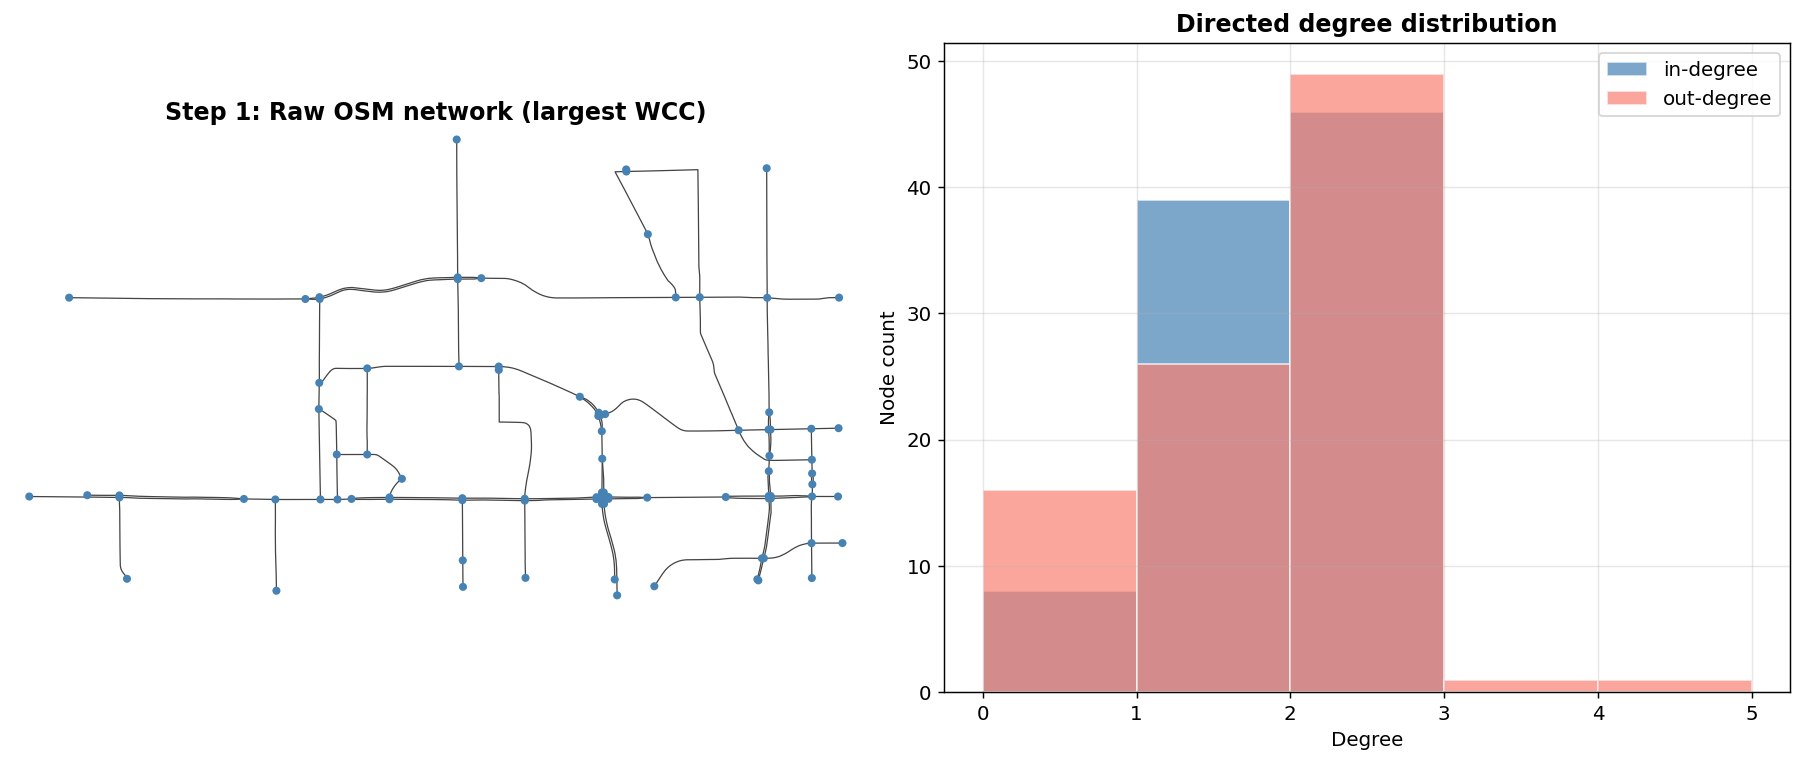

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Map
ox.plot_graph(G_osm, ax=axes[0], node_size=20, edge_linewidth=0.7,
              bgcolor='white', node_color='steelblue', edge_color='#444',
              show=False, close=False)
axes[0].set_title('Step 1: Raw OSM network (largest WCC)', fontweight='bold')

# Degree distribution
in_d  = [d for _, d in G_osm.in_degree()]
out_d = [d for _, d in G_osm.out_degree()]
bins  = range(max(max(in_d), max(out_d)) + 2)
axes[1].hist(in_d,  bins=bins, alpha=0.7, color='steelblue', label='in-degree',  edgecolor='white')
axes[1].hist(out_d, bins=bins, alpha=0.7, color='salmon',    label='out-degree', edgecolor='white')
axes[1].set_xlabel('Degree'); axes[1].set_ylabel('Node count')
axes[1].set_title('Directed degree distribution', fontweight='bold')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('viz_step1.png', bbox_inches='tight'); plt.show()


## Step 2 — Standardize road tags (osmfilter)
Strips non-essential OSM tags (speed limits, lane counts, surface, names)
so netconvert gets a clean, uniform input.


Step 2 — tags: 1147 → 711  (−436, 38.0%)


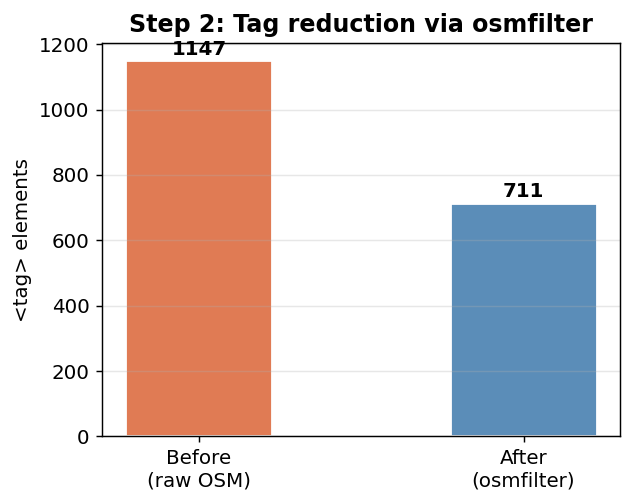

In [5]:
if REGEN:
    result = subprocess.run([
        'osmfilter', 'ames_campus.osm',
        '--drop-tags=maxspeed=* maxspeed:forward=* maxspeed:backward=* '
                    'lanes=* lanes:forward=* lanes:backward=* '
                    'turn:lanes=* surface=* name=* ref=*',
        '-o=ames_campus_clean.osm',
    ], capture_output=True, text=True, check=True)

def _count_tags(path):
    with open(path) as f:
        return len(re.findall(r'<tag ', f.read()))

before = _count_tags('ames_campus.osm')
after  = _count_tags('ames_campus_clean.osm')
print(f'Step 2 — tags: {before} → {after}  (−{before-after}, {(before-after)/before*100:.1f}%)')

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['Before\n(raw OSM)', 'After\n(osmfilter)'], [before, after],
              color=['#e07b54', '#5b8db8'], edgecolor='white', width=0.45)
for bar, v in zip(bars, [before, after]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 8,
            str(v), ha='center', va='bottom', fontweight='bold')
ax.set_ylabel('<tag> elements'); ax.grid(axis='y', alpha=0.3)
ax.set_title('Step 2: Tag reduction via osmfilter', fontweight='bold')
plt.tight_layout()
plt.savefig('viz_step2.png', bbox_inches='tight'); plt.show()


## Step 3 — First netconvert pass (raw SUMO net)
Converts cleaned OSM → SUMO `.net.xml`, merging geometry, joining nearby junctions
(`--junctions.join-dist 50`), and joining parallel edges.
Output: `ames_campus_raw.net.xml` — intermediate net before degree-2 cleanup.


In [6]:
if REGEN:
    type_files = (
        f'{SUMO_HOME}/data/typemap/osmNetconvert.typ.xml,'
        f'{SUMO_HOME}/data/typemap/osmNetconvertUrbanDe.typ.xml'
    )
    subprocess.run([
        'netconvert',
        '--osm-files',           'ames_campus_clean.osm',
        '--output-file',         'ames_campus_raw.net.xml',
        '--type-files',          type_files,
        '--geometry.remove',
        '--edges.join',
        '--junctions.join',
        '--junctions.join-dist', '50',
        '--roundabouts.guess',   'false',
        '--tls.discard-loaded',  'true',
        '--tls.guess',           'false',
        '--tls.guess-signals',   'false',
        '--sidewalks.guess',     'false',
        '--crossings.guess',     'false',
        '--walkingareas',        'false',
        '--keep-edges.by-vclass','passenger',
        '--no-turnarounds',
    ], check=True)

net_raw  = sumolib.net.readNet('ames_campus_raw.net.xml')
junc_raw = [j for j in net_raw.getNodes() if j.getType() != 'internal']
edge_raw = [e for e in net_raw.getEdges() if not e.getID().startswith(':')]
print(f'Step 3 — {len(junc_raw)} junctions, {len(edge_raw)} edges')


Step 3 — 74 junctions, 162 edges


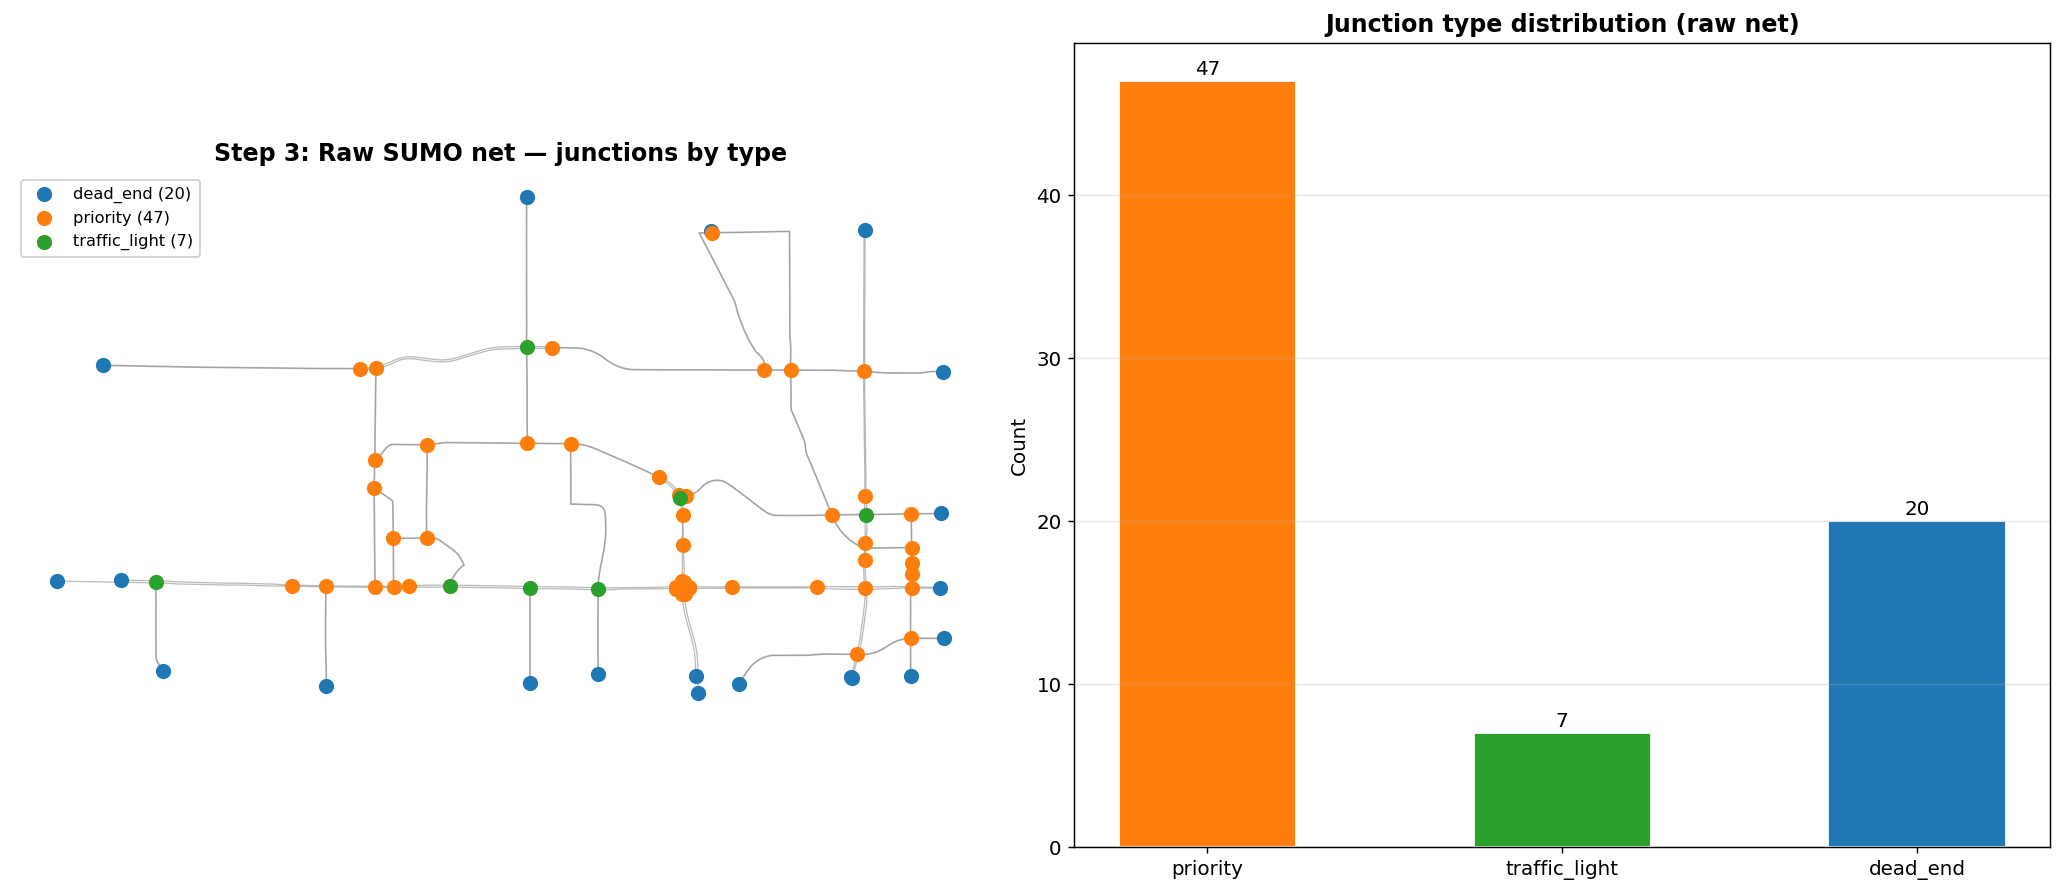

In [7]:
cmap       = plt.cm.tab10
junc_types = sorted(set(j.getType() for j in junc_raw))
type_color = {t: cmap(i) for i, t in enumerate(junc_types)}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ax = axes[0]
for e in edge_raw:
    sh = e.getShape()
    if len(sh) >= 2:
        xs, ys = zip(*sh)
        ax.plot(xs, ys, '-', color='#777', lw=0.7, alpha=0.5, zorder=1)
for jtype in junc_types:
    js = [j for j in junc_raw if j.getType() == jtype]
    ax.scatter([j.getCoord()[0] for j in js], [j.getCoord()[1] for j in js],
               s=55, color=type_color[jtype], label=f'{jtype} ({len(js)})', zorder=3)
ax.legend(fontsize=9, framealpha=0.9)
ax.set_title('Step 3: Raw SUMO net — junctions by type', fontweight='bold')
ax.set_aspect('equal'); ax.axis('off')

ax2 = axes[1]
tc  = Counter(j.getType() for j in junc_raw)
b   = ax2.bar(list(tc.keys()), list(tc.values()),
              color=[type_color[t] for t in tc], edgecolor='white', width=0.5)
for bar, v in zip(b, tc.values()):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
             str(v), ha='center', va='bottom')
ax2.set_ylabel('Count'); ax2.grid(axis='y', alpha=0.3)
ax2.set_title('Junction type distribution (raw net)', fontweight='bold')

plt.tight_layout()
plt.savefig('viz_step3_raw.png', bbox_inches='tight'); plt.show()


## Step 4 — Remove degree-2 junctions + rebuild SUMO net
Builds an undirected graph from the raw SUMO net, iteratively removes pass-through
(degree-2) junctions by bridging their two neighbours, then reconstructs the SUMO
net from plain node/edge XML so the saved file exactly matches the simplified graph.

Bridge edges inherit lane/speed/priority attributes from the first directed SUMO edge
found along the traced path through removed intermediate nodes.


In [8]:
# Build undirected graph from raw SUMO net
G_sumo = nx.Graph()
for j in junc_raw:
    G_sumo.add_node(j.getID(), x=j.getCoord()[0], y=j.getCoord()[1])
for e in edge_raw:
    u, v = e.getFromNode().getID(), e.getToNode().getID()
    if u in G_sumo and v in G_sumo:
        G_sumo.add_edge(u, v)

deg_dist_before = Counter(d for _, d in G_sumo.degree())
print(f'Before: {G_sumo.number_of_nodes()} nodes, {G_sumo.number_of_edges()} edges')
print('Degree distribution:', dict(sorted(deg_dist_before.items())))

def remove_degree2_nodes(G):
    G = G.copy()
    changed = True
    while changed:
        changed = False
        for node in list(G.nodes()):
            if G.degree(node) == 2:
                u, v = list(G.neighbors(node))
                if not G.has_edge(u, v):
                    G.add_edge(u, v)
                G.remove_node(node)
                changed = True
                break
    return G

G_simplified   = remove_degree2_nodes(G_sumo)
nodes_to_remove = set(G_sumo.nodes()) - set(G_simplified.nodes())
print(f'Removed {len(nodes_to_remove)} degree-2 nodes')
print(f'After:  {G_simplified.number_of_nodes()} nodes, {G_simplified.number_of_edges()} edges')


Before: 74 nodes, 95 edges
Degree distribution: {1: 20, 2: 11, 3: 30, 4: 10, 5: 2, 8: 1}
Removed 11 degree-2 nodes
After:  63 nodes, 84 edges


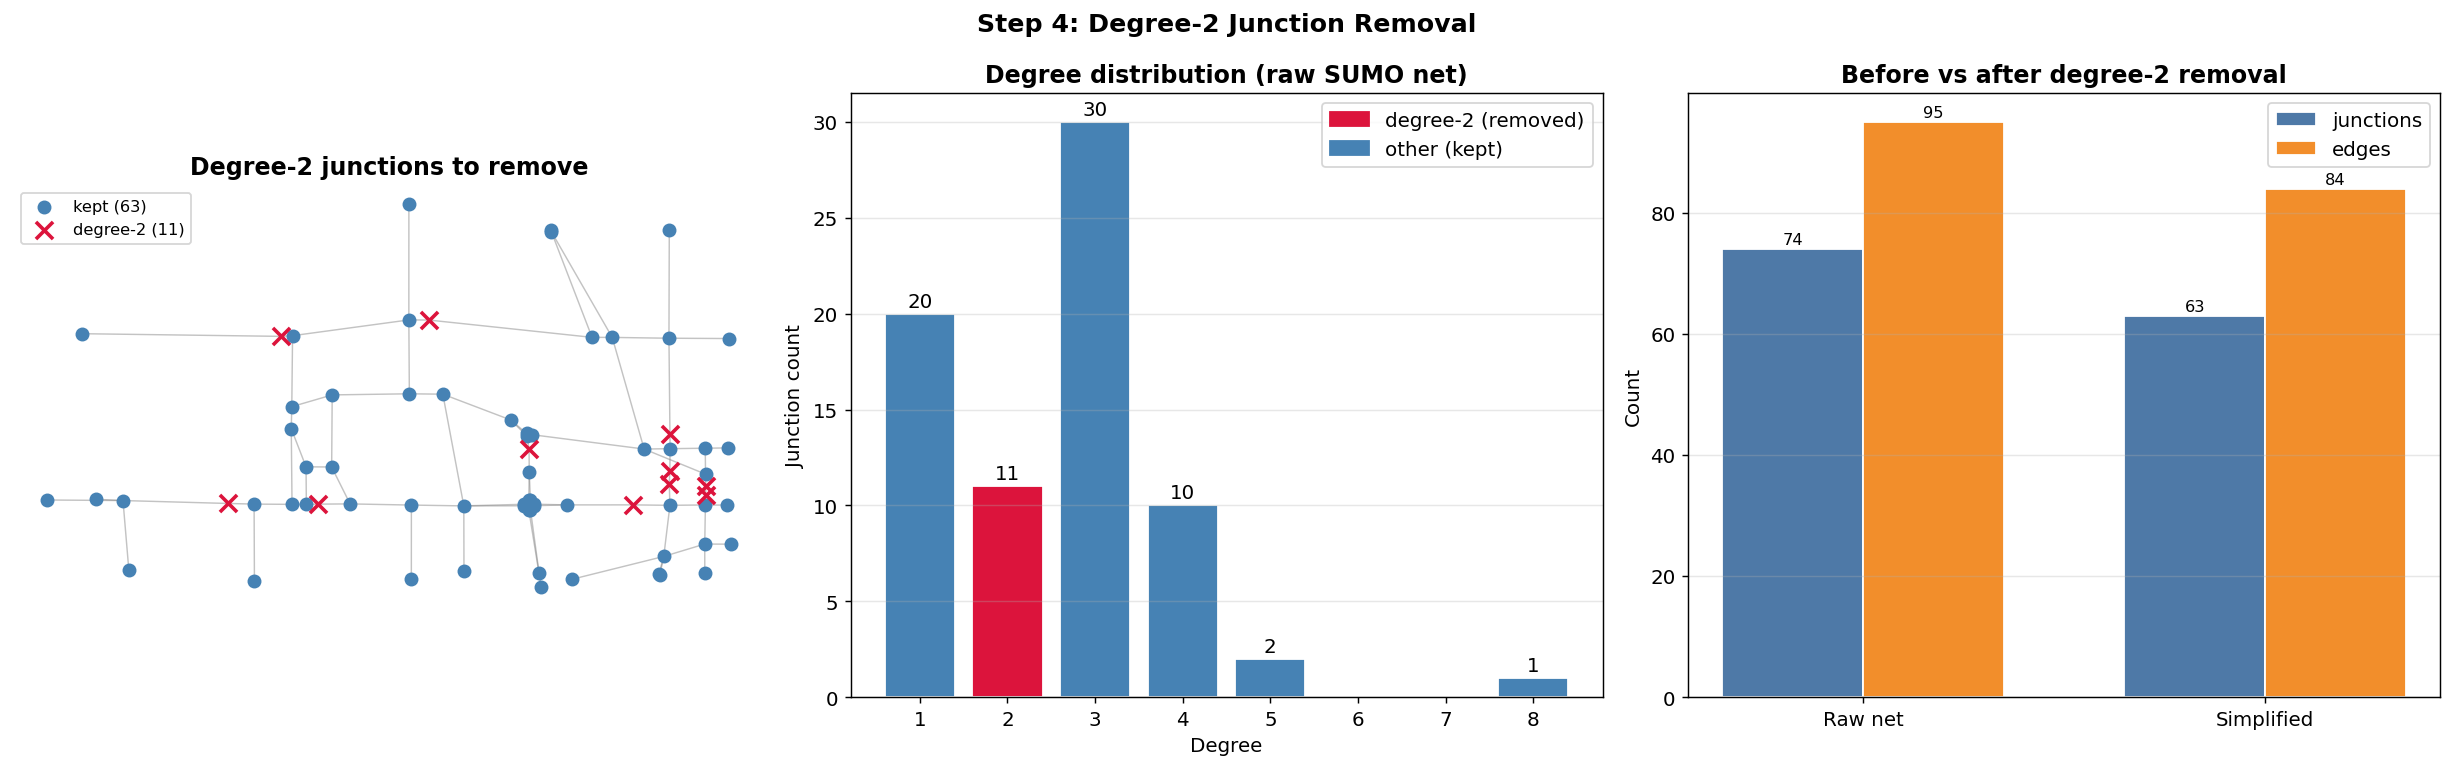

In [9]:
pos = {n: (G_sumo.nodes[n]['x'], G_sumo.nodes[n]['y']) for n in G_sumo.nodes()}

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

# Left: map with degree-2 nodes highlighted
ax = axes[0]
for u, v in G_sumo.edges():
    ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]],
            '-', color='#888', lw=0.8, alpha=0.5, zorder=1)
kept  = [n for n in G_sumo if n not in nodes_to_remove]
remov = list(nodes_to_remove)
ax.scatter([pos[n][0] for n in kept],  [pos[n][1] for n in kept],
           s=45, color='steelblue', label=f'kept ({len(kept)})', zorder=3)
ax.scatter([pos[n][0] for n in remov], [pos[n][1] for n in remov],
           s=90, color='crimson', marker='x', linewidths=2,
           label=f'degree-2 ({len(remov)})', zorder=4)
ax.legend(fontsize=9)
ax.set_title('Degree-2 junctions to remove', fontweight='bold')
ax.set_aspect('equal'); ax.axis('off')

# Middle: degree distribution
ax2 = axes[1]
degs   = sorted(deg_dist_before.keys())
colors = ['crimson' if d == 2 else 'steelblue' for d in degs]
bars   = ax2.bar(degs, [deg_dist_before[d] for d in degs], color=colors, edgecolor='white')
for bar, d in zip(bars, degs):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
             str(deg_dist_before[d]), ha='center', va='bottom')
ax2.set_xlabel('Degree'); ax2.set_ylabel('Junction count')
ax2.set_title('Degree distribution (raw SUMO net)', fontweight='bold')
ax2.legend(handles=[mpatches.Patch(color='crimson',   label='degree-2 (removed)'),
                    mpatches.Patch(color='steelblue', label='other (kept)')])
ax2.grid(axis='y', alpha=0.3)

# Right: before / after bar chart
ax3 = axes[2]
stages  = ['Raw net', 'Simplified']
n_nodes = [G_sumo.number_of_nodes(),      G_simplified.number_of_nodes()]
n_edges = [G_sumo.number_of_edges(),      G_simplified.number_of_edges()]
x = np.arange(2); w = 0.35
b1 = ax3.bar(x - w/2, n_nodes, w, label='junctions', color='#4e79a7', edgecolor='white')
b2 = ax3.bar(x + w/2, n_edges, w, label='edges',     color='#f28e2b', edgecolor='white')
for bar in list(b1) + list(b2):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             str(int(bar.get_height())), ha='center', va='bottom', fontsize=9)
ax3.set_xticks(x); ax3.set_xticklabels(stages)
ax3.set_ylabel('Count'); ax3.legend(); ax3.grid(axis='y', alpha=0.3)
ax3.set_title('Before vs after degree-2 removal', fontweight='bold')

plt.suptitle('Step 4: Degree-2 Junction Removal', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('viz_step4_removal.png', bbox_inches='tight'); plt.show()


/tmp/ipykernel_107611/15678500.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


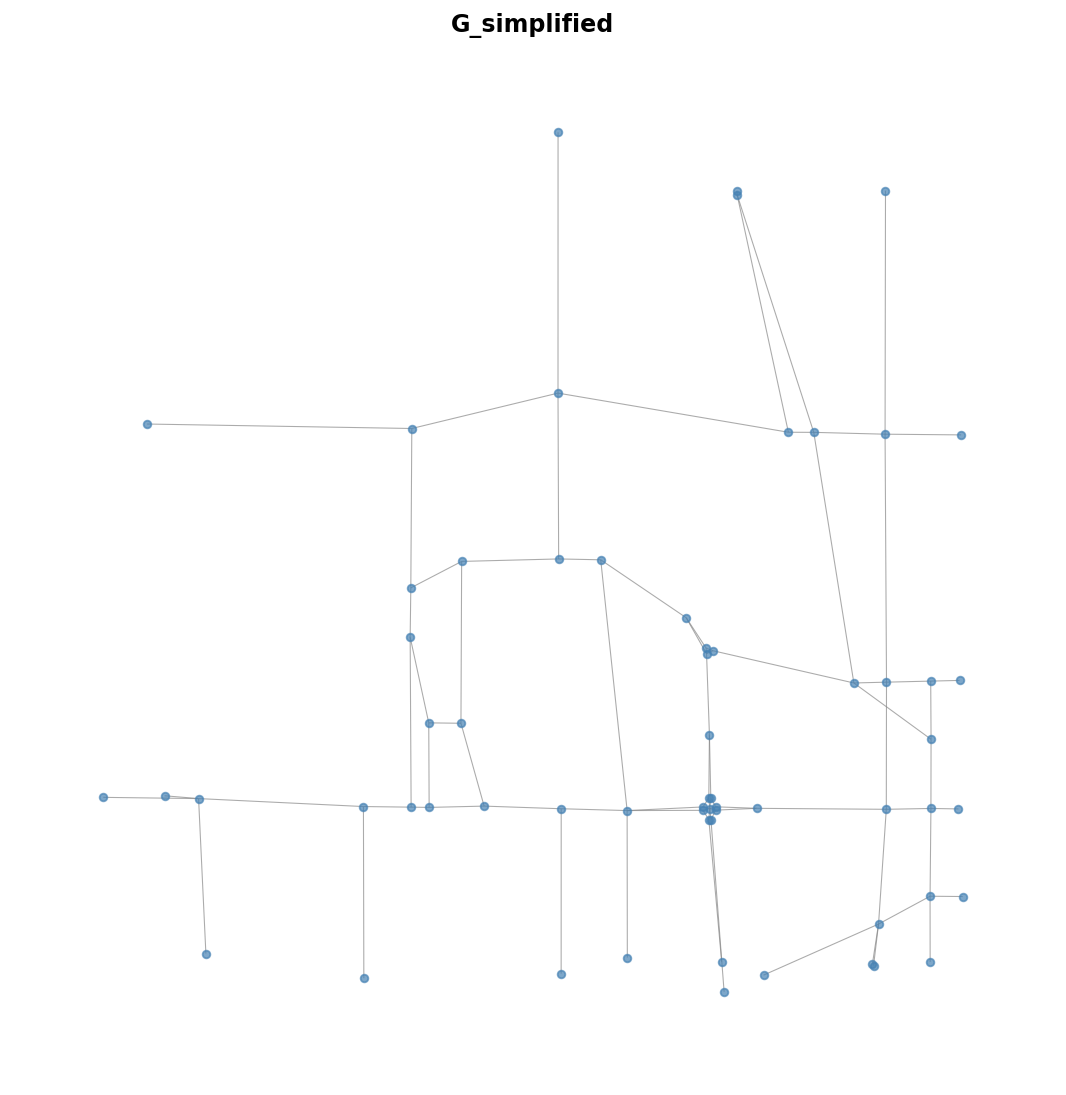

In [10]:
pos = {n: (G_simplified.nodes[n]['x'], G_simplified.nodes[n]['y'])
       for n in G_simplified.nodes()}

plt.figure(figsize=(8, 8))
nx.draw(G_simplified, pos=pos,
        node_size=18, node_color='steelblue',
        edge_color='#888', width=0.6, alpha=0.7)
plt.title('G_simplified', fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

In [15]:
if REGEN:
    full_pos = {j.getID(): j.getCoord()
                for j in net_raw.getNodes() if j.getType() != 'internal'}
    sumo_dir_edges = {(e.getFromNode().getID(), e.getToNode().getID()): e
                      for e in net_raw.getEdges() if not e.getID().startswith(':')}

    def trace_path(u, v):
        stack, visited = [(u, [u])], {u}
        while stack:
            curr, path = stack.pop()
            for nbr in G_sumo.neighbors(curr):
                if nbr in visited:
                    continue
                new_path = path + [nbr]
                if nbr == v:
                    return new_path
                if nbr in nodes_to_remove:
                    visited.add(nbr)
                    stack.append((nbr, new_path))
        return [u, v]

    nod_root = ET.Element('nodes')
    for nid in G_simplified.nodes():
        x, y = full_pos[nid]
        ET.SubElement(nod_root, 'node', id=nid, x=f'{x:.2f}', y=f'{y:.2f}', type='priority')
    ET.ElementTree(nod_root).write('tmp_nodes.xml', encoding='unicode', xml_declaration=True)

    edg_root, written = ET.Element('edges'), set()
    for u, v in G_simplified.edges():
        path_uv = trace_path(u, v)
        path_vu = list(reversed(path_uv))
        for a, b, path in [(u, v, path_uv), (v, u, path_vu)]:
            if (a, b) in written:
                continue
            ref = next((sumo_dir_edges[(x, y)]
                        for x, y in zip(path[:-1], path[1:])
                        if (x, y) in sumo_dir_edges), None)
            if ref is None:
                continue
            el = ET.SubElement(edg_root, 'edge')
            el.set('id',       f'{a}_to_{b}')
            el.set('from',     a);  el.set('to', b)
            el.set('numLanes', str(ref.getLaneNumber()))
            el.set('speed',    str(ref.getSpeed()))
            el.set('priority', str(ref.getPriority()))
            el.set('shape',    ' '.join(f'{full_pos[n][0]:.2f},{full_pos[n][1]:.2f}'
                                        for n in path if n in full_pos))
            written.add((a, b))
    ET.ElementTree(edg_root).write('tmp_edges.xml', encoding='unicode', xml_declaration=True)

    subprocess.run([
        'netconvert',
        '--node-files', 'tmp_nodes.xml', '--edge-files', 'tmp_edges.xml',
        '--output-file', 'ames_campus.net.xml', '--no-turnarounds',
    ], check=True)
    for f in ('tmp_nodes.xml', 'tmp_edges.xml'):
        os.remove(f)
    print('Step 4 done — ames_campus.net.xml written')


## Step 5 — Manual network surgery (netedit)
Open `ames_campus.net.xml` in netedit, remove any remaining unwanted edges or
isolated fragments, then **save back to `ames_campus.net.xml`**.
Run the cells below after saving to inspect the result.


In [1]:
net_pruned  = sumolib.net.readNet('ames_campus.net.xml')
junc_pruned = [j for j in net_pruned.getNodes() if j.getType() != 'internal']
edge_pruned = [e for e in net_pruned.getEdges() if not e.getID().startswith(':')]
print(f'Step 5 — {len(junc_pruned)} junctions, {len(edge_pruned)} directed edges')
print(f'  Junctions removed vs Step 4: {G_simplified.number_of_nodes() - len(junc_pruned)}')


NameError: name 'sumolib' is not defined

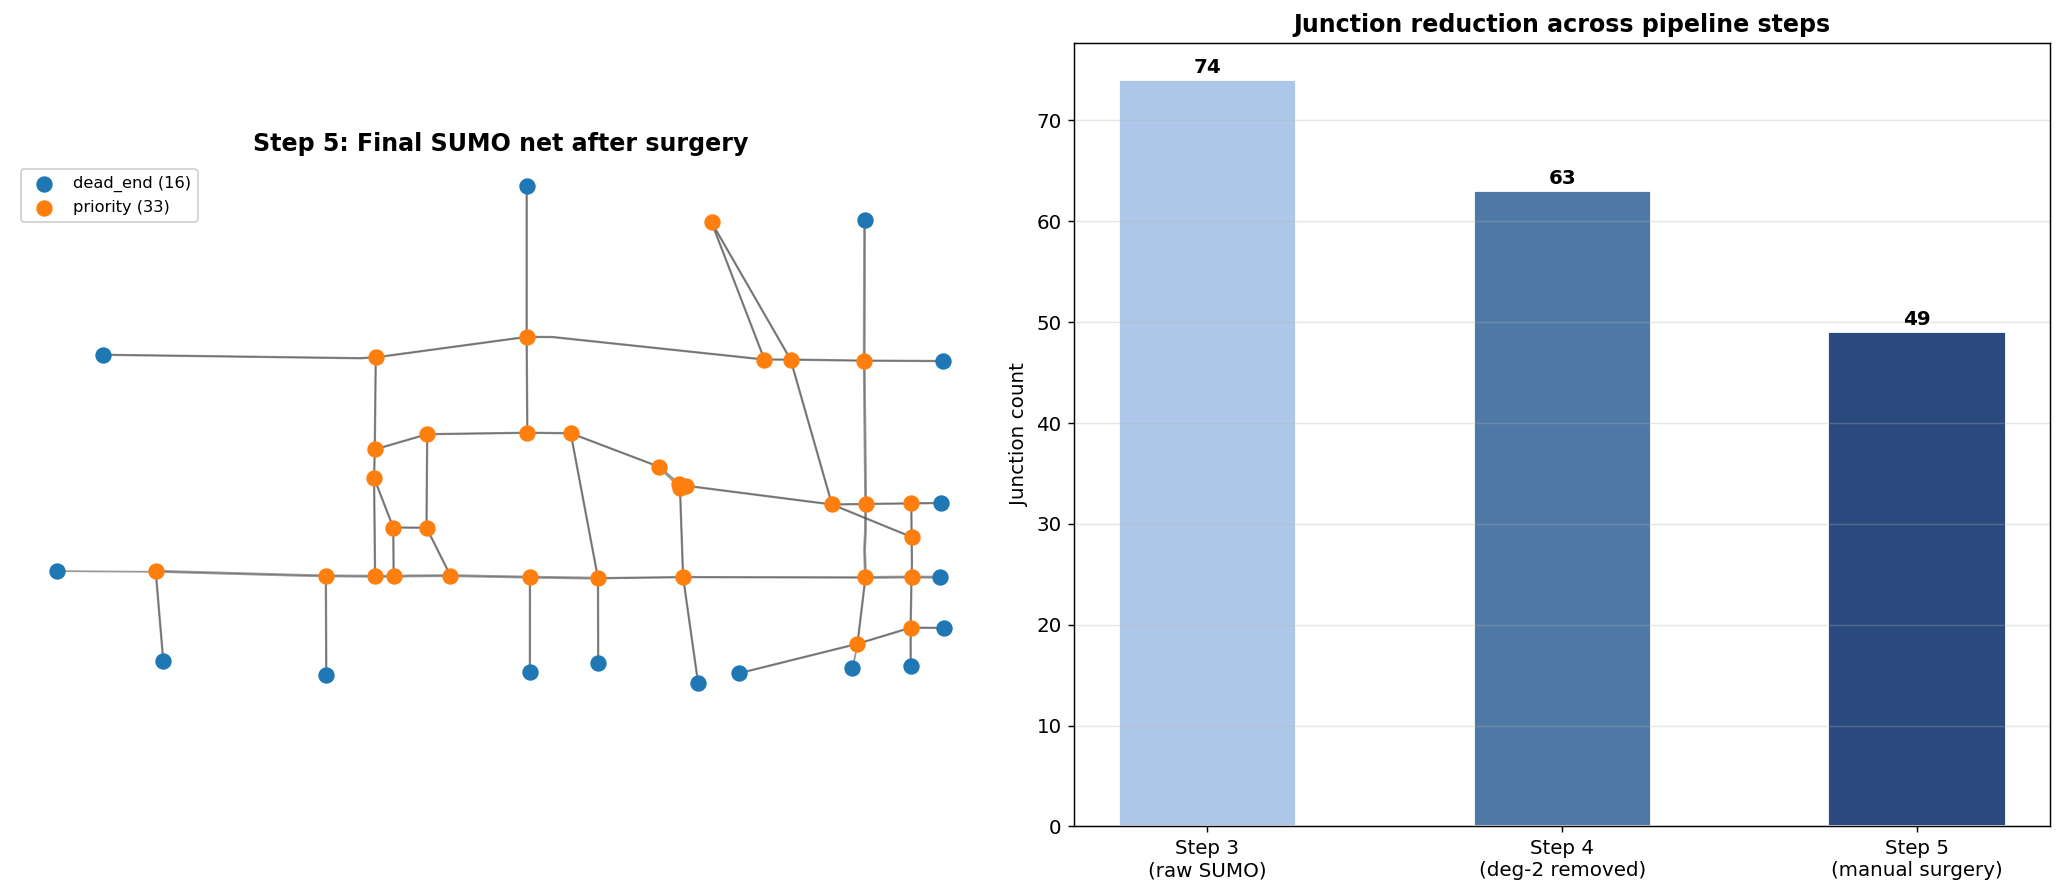

In [12]:
junc_types_p = sorted(set(j.getType() for j in junc_pruned))
type_color_p = {t: cmap(i) for i, t in enumerate(junc_types_p)}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: final network map
ax = axes[0]
for e in edge_pruned:
    sh = e.getShape()
    if len(sh) >= 2:
        xs, ys = zip(*sh)
        ax.plot(xs, ys, '-', color='#555', lw=1.0, alpha=0.6, zorder=1)
for jtype in junc_types_p:
    js = [j for j in junc_pruned if j.getType() == jtype]
    ax.scatter([j.getCoord()[0] for j in js], [j.getCoord()[1] for j in js],
               s=65, color=type_color_p[jtype],
               label=f'{jtype} ({len(js)})', zorder=3)
ax.legend(fontsize=9, framealpha=0.9)
ax.set_title('Step 5: Final SUMO net after surgery', fontweight='bold')
ax.set_aspect('equal'); ax.axis('off')

# Right: junction count across all three processing steps (comparable units)
ax2 = axes[1]
stages = ['Step 3\n(raw SUMO)', 'Step 4\n(deg-2 removed)', 'Step 5\n(manual surgery)']
counts = [len(junc_raw), G_simplified.number_of_nodes(), len(junc_pruned)]
colors = ['#aec7e8', '#4e79a7', '#2a4a7f']
bars   = ax2.bar(stages, counts, color=colors, edgecolor='white', width=0.5)
for bar, v in zip(bars, counts):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             str(v), ha='center', va='bottom', fontweight='bold')
ax2.set_ylabel('Junction count'); ax2.grid(axis='y', alpha=0.3)
ax2.set_title('Junction reduction across pipeline steps', fontweight='bold')

plt.tight_layout()
plt.savefig('viz_step5.png', bbox_inches='tight'); plt.show()


## Summary


In [13]:
rows = [
    ('OSM nodes (raw)',                   G_osm.number_of_nodes()),
    ('OSM edges (raw)',                   G_osm.number_of_edges()),
    ('SUMO junctions (Step 3 raw)',       len(junc_raw)),
    ('SUMO edges (Step 3 raw)',           len(edge_raw)),
    ('Degree-2 junctions removed',        len(nodes_to_remove)),
    ('SUMO junctions (Step 4 simplified)',G_simplified.number_of_nodes()),
    ('SUMO edges (Step 4 simplified)',    G_simplified.number_of_edges()),
    ('SUMO junctions (Step 5 final)',     len(junc_pruned)),
    ('SUMO edges (Step 5 final)',         len(edge_pruned)),
]
w = max(len(r[0]) for r in rows)
print('Pipeline summary')
print('─' * (w + 12))
for label, val in rows:
    print(f'  {label:<{w}}  {val}')


Pipeline summary
──────────────────────────────────────────────
  OSM nodes (raw)                     93
  OSM edges (raw)                     131
  SUMO junctions (Step 3 raw)         74
  SUMO edges (Step 3 raw)             162
  Degree-2 junctions removed          11
  SUMO junctions (Step 4 simplified)  63
  SUMO edges (Step 4 simplified)      84
  SUMO junctions (Step 5 final)       49
  SUMO edges (Step 5 final)           120
